## **Regularisasi pada Model Linier**
Memberikan penailti pada koefisien besar untuk mencegah overfitting.

Tujuannya:
- Model lebih sederhana
- Tidak terlalu mengikuti noise
- Lebih baik saat memprediksi data baru

Jenis Regularisasi:
- **Ridge Regression**: mengecilkan semua koefisien.
- **Lasso Regression**: mengecilkan koefisien, sebagian menjadi nol.

Ridge dipakai kapan?:
- Mengecilkan semua koefisien.
- Semua fitur tetap digunakan.
- Cocok jika semua fitur penting.

Lasso dipakai kapan?:
- Sebagian koefisien bisa menjadi 0.
- Bisa melakukan seleksi fitur.
- Cocok jika ada fitur yang kurang relevan.

**Alpha** merupakan kekuatan regularisasi. Semakin besar nilai alpha, semakin kuat regularisasinya.

Regularisasi digunakan untuk menyeimbangkan **Bias** dan **Variance**. Jika **variance tinggi**, maka model terlalu rumit (overfitting). Jika **bias tinggi**, maka model terlalu sederhana (underfitting).

## **Studi Kasus: Kekuatan Beton**
- Tujuan: memprediksi kekuatan tekan menggunakan model linier terregularisasi.
- Cara Menyelesaikan Studi Kasus
    - Terapkan Regularisasi: Gunakan regresi Ridge atau Lasso.
    - Bandingkan Model: Evaluasi kinerja terhadap model tanpa regularisasi.
    - Sesuaikan Alpha: Sesuaikan kekuatan regularisasi untuk menyeimbangkan bias dan varians.

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso

from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score

In [15]:
df = pd.read_csv(r'E:\DigitalentDA\Datasets\concrete_data.csv')

print(df.head(10))
df.info()
df.describe()

   Cement  Blast Furnace Slag  Fly Ash  Water  Superplasticizer  \
0   540.0                 0.0      0.0  162.0               2.5   
1   540.0                 0.0      0.0  162.0               2.5   
2   332.5               142.5      0.0  228.0               0.0   
3   332.5               142.5      0.0  228.0               0.0   
4   198.6               132.4      0.0  192.0               0.0   
5   266.0               114.0      0.0  228.0               0.0   
6   380.0                95.0      0.0  228.0               0.0   
7   380.0                95.0      0.0  228.0               0.0   
8   266.0               114.0      0.0  228.0               0.0   
9   475.0                 0.0      0.0  228.0               0.0   

   Coarse Aggregate  Fine Aggregate  Age  Strength  
0            1040.0           676.0   28     79.99  
1            1055.0           676.0   28     61.89  
2             932.0           594.0  270     40.27  
3             932.0           594.0  365     41.05

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Strength
count,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.167864,73.895825,54.188350,181.567282,6.204660,972.918932,773.580485,45.662136,35.817961
std,104.506364,86.279342,63.997004,21.354219,5.973841,77.753954,80.175980,63.169912,16.705742
min,102.000000,0.000000,0.000000,121.800000,0.000000,801.000000,594.000000,1.000000,2.330000
25%,192.375000,0.000000,0.000000,164.900000,0.000000,932.000000,730.950000,7.000000,23.710000
50%,272.900000,22.000000,0.000000,185.000000,6.400000,968.000000,779.500000,28.000000,34.445000
75%,350.000000,142.950000,118.300000,192.000000,10.200000,1029.400000,824.000000,56.000000,46.135000
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.600000


In [16]:
print(df.isnull().sum())

Cement                0
Blast Furnace Slag    0
Fly Ash               0
Water                 0
Superplasticizer      0
Coarse Aggregate      0
Fine Aggregate        0
Age                   0
Strength              0
dtype: int64


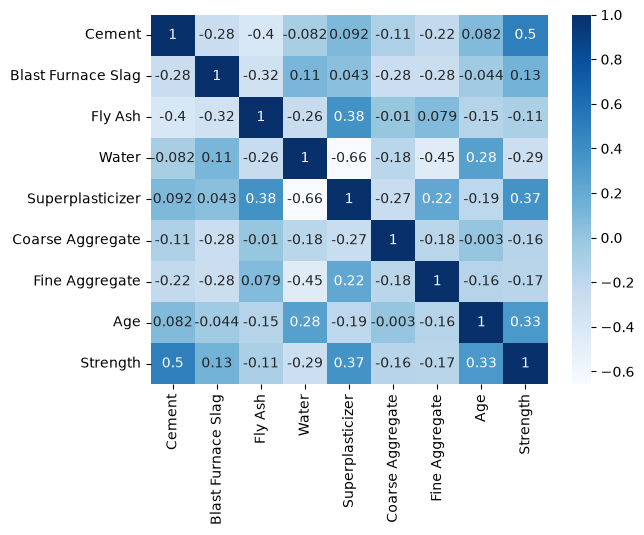

In [17]:
sns.heatmap(df.corr(), annot=True, cmap='Blues')
plt.show()

In [18]:
X = df.drop(columns=['Strength'])
y = df['Strength']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [19]:
# Tanpa Regularisasi
model = LinearRegression()
model.fit(X_train, y_train)

pred_linear = model.predict(X_test)

In [20]:
print("Linear")
print("MSE :", mean_squared_error(y_test, pred_linear))
print("MAE :", mean_absolute_error(y_test, pred_linear))
print("R2  :", r2_score(y_test, pred_linear))

Linear
MSE : 95.97094009110684
MAE : 7.745559243921435
R2  : 0.6275531792314848


In [30]:
# Ridge Regression
m_ridge = Ridge(alpha=1)
m_ridge.fit(X_train, y_train)

pred_ridge = m_ridge.predict(X_test)

In [34]:
print("Ridge")
print("MSE :", mean_squared_error(y_test, pred_ridge))
print("MAE :", mean_absolute_error(y_test, pred_ridge))
print("R2  :", r2_score(y_test, pred_ridge))

Ridge
MSE : 95.97089554036006
MAE : 7.745553967204023
R2  : 0.6275533521253212


In [33]:
# Lasso Regression
m_lasso = Lasso(alpha=1)
m_lasso.fit(X_train, y_train)

pred_lasso = m_lasso.predict(X_test)

print("Lasso")
print("MSE :", mean_squared_error(y_test, pred_ridge))
print("MAE :", mean_absolute_error(y_test, pred_ridge))
print("R2  :", r2_score(y_test, pred_ridge))

Lasso
MSE : 95.97089554036006
MAE : 7.745553967204023
R2  : 0.6275533521253212


- **MSE lebih kecil** → lebih baik.
- **MAE lebih kecil** → rata-rata kesalahan prediksi lebih kecil.
- **R² lebih besar** → model menjelaskan lebih banyak variasi data.

In [ ]:
# alphas = [1, 10, 100, 1000, 5000]

# for alpha in alphas:
#     model = Ridge(alpha=alpha)
#     model.fit(X_train, y_train)

#     pred = model.predict(X_test)

#     print(
#         f"Alpha={alpha:<5} "
#         f"R²={r2_score(y_test, pred):.7f} "
#         f"MSE={mean_squared_error(y_test, pred):.7f}"
#     )

Alpha=1     R²=0.6275534 MSE=95.9708955
Alpha=10    R²=0.6275549 MSE=95.9704959
Alpha=100   R²=0.6275699 MSE=95.9666255
Alpha=1000  R²=0.6276778 MSE=95.9388267
Alpha=5000  R²=0.6276540 MSE=95.9449609
